# CO4194 7000094 TrackA Code
## Track A: XR Learning Assistant
This project explores education and training in extended reality (XR). You will work with a synthetic dataset of learner sessions. Each row summarises how a learner interacted with the system, including session duration, attention ratio, time of day, modality counts (video, reading, audio), and the previous quiz mean. Targets include the next quiz score, time to mastery, and whether additional support is required.
### 1. Data and Preprocessing
#### 1.1 Import Libraries

In [1]:
import numpy as numpy
import pandas as pandas
import matplotlib.pyplot as pyplot
import seaborn as seaborn

KeyboardInterrupt: 

#### 1.2 Get Dataset

In [2]:
xr_learner_sessions_df = pandas.read_csv("../datasets/xr_learner_sessions.csv")

#### 1.3 Explore the Dataset
1.3.1 Check the shape

In [3]:
print(f"shape: {xr_learner_sessions_df.shape}")

shape: (2662, 35)


1.3.2 Check the data types

In [4]:
xr_learner_sessions_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2662 entries, 0 to 2661
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   session_id                      2662 non-null   str    
 1   learner_id                      2662 non-null   str    
 2   session_index                   2662 non-null   int64  
 3   session_start_iso               2662 non-null   str    
 4   day_of_week                     2662 non-null   str    
 5   time_of_day                     2662 non-null   str    
 6   days_since_prev_session         2302 non-null   float64
 7   device_type                     2662 non-null   str    
 8   input_mode                      2662 non-null   str    
 9   accessibility_nonvoice_enabled  2662 non-null   int64  
 10  avg_latency_ms                  2662 non-null   float64
 11  tracking_loss_ratio             2662 non-null   float64
 12  session_duration_min            2662 non-null

The columns are as follows;

- cat: "session_id", "learner_id", "session_start_iso", "day_of_week", "time_of_day", "device_type", "input_mode", "dominant_modality", "split"
- cat_excluded: "session_id", "learner_id", "session_start_iso"

- num: "session_index", "days_since_prev_session", "accessibility_nonvoice_enabled", "avg_latency_ms", "tracking_loss_ratio", "session_duration_min", "attention_ratio", "active_time_ratio", "pause_count", "help_request_count", "hint_time_sec", "error_count", "completion_rate", "video_count", "reading_count", "audio_count", "practice_count", "modality_switches", "prev_quiz_mean", "prev_quiz_last", "prev_quiz_attempts", "prior_mastery_level", "confidence_rating", "next_quiz_score", "time_to_mastery_days", "support_required"
- num_excluded: "session_index"

1.3.3 Exclude sensitive columns

In [5]:
xr_learner_sessions_df = xr_learner_sessions_df.drop(columns=["session_id", "learner_id", "session_start_iso", "session_index"])

1.3.4 Check for missing values

In [6]:
print(xr_learner_sessions_df.isnull().sum())

day_of_week                         0
time_of_day                         0
days_since_prev_session           360
device_type                         0
input_mode                          0
accessibility_nonvoice_enabled      0
avg_latency_ms                      0
tracking_loss_ratio                 0
session_duration_min                0
attention_ratio                     0
active_time_ratio                   0
pause_count                         0
help_request_count                  0
hint_time_sec                       0
error_count                         0
completion_rate                     0
video_count                         0
reading_count                       0
audio_count                         0
practice_count                      0
modality_switches                   0
dominant_modality                   0
prev_quiz_mean                    360
prev_quiz_last                    360
prev_quiz_attempts                  0
prior_mastery_level                 0
confidence_r

Since it is the "next_quiz_score" feature that we want to predict, we will first check for which other numerical features it is correlated with. We will use the correlation matrix to check for this.

1.3.5 Check correlation matrix

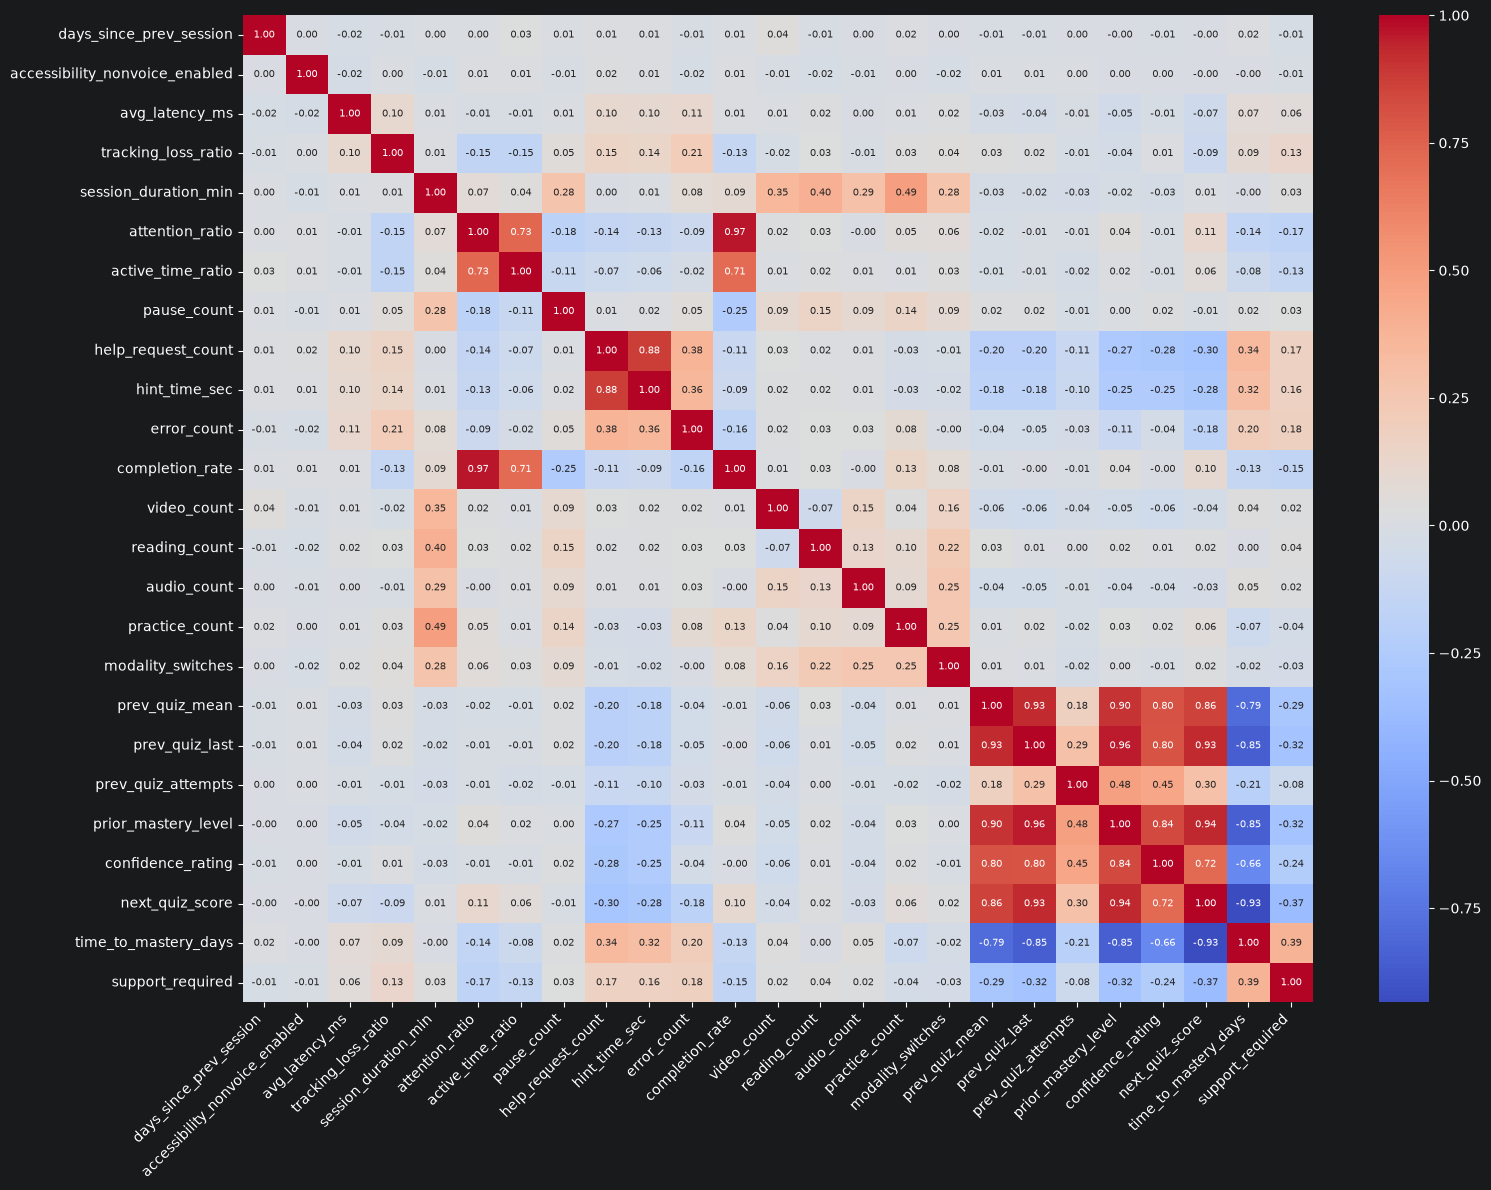

In [7]:
correlation_matrix = xr_learner_sessions_df.corr(numeric_only=True)
pyplot.figure(figsize=(16, 12))

seaborn.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    annot_kws={"size": 7}
)

pyplot.xticks(rotation=45, ha="right")
pyplot.yticks(rotation=0)
pyplot.tight_layout()
pyplot.show()

We can see that the "next_quiz_score" feature is most correlated with the "prio_mastery_level" feature with a correlation of 0.94. The "completion_rate" is most correlated with the "attention_ratio" with the score 0.97 which is the highest positive correlation score.

#### 1.4 Feature Engineering

1.4.1 Identify numerical and categorical features

In [8]:
num_features = ["days_since_prev_session", "accessibility_nonvoice_enabled", "avg_latency_ms", "tracking_loss_ratio", "session_duration_min", "attention_ratio", "active_time_ratio", "pause_count", "help_request_count", "hint_time_sec", "error_count", "completion_rate", "video_count", "reading_count", "audio_count", "practice_count", "modality_switches", "prev_quiz_mean", "prev_quiz_last", "prev_quiz_attempts", "prior_mastery_level", "confidence_rating", "time_to_mastery_days", "support_required"]

cat_features = ["day_of_week", "time_of_day", "device_type", "input_mode", "dominant_modality", "split"]

1.4.2 Get needed libraries for preprocessing and modeling

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

1.4.3 Pipeline for numerical features

In [10]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

1.4.4 Pipeline for categorical features

In [11]:
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

1.4.5 Combine the two pipelines into a single preprocessor

In [12]:
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_features),
    ("cat", categorical_transformer, cat_features),
])

### 2. Regression
First choose the target feature and the features to use for the models. The target feature is "next_quiz_score" and the features to use are the numerical features and the categorical features.
#### 2.1 Define the target and features
2.1.1 set 'y' target variable and 'x' features to use for the models

In [13]:
y = xr_learner_sessions_df["next_quiz_score"]
x = xr_learner_sessions_df.drop(columns=y.name)

2.1.2 Split the dataset into training and testing sets. We will use 80% of the data for training and 20% for testing.

In [14]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

#### 2.2 Linear regression pipeline

In [15]:
from sklearn.linear_model import LinearRegression

linear_regression = Pipeline([
    ("preprocess", preprocessor),
    ("model", LinearRegression())
])

#### 2.3 Random forest regression pipeline

In [16]:
from sklearn.ensemble import RandomForestRegressor

random_forest_regression = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestRegressor(n_estimators=100, random_state=42))
])

#### 2.4 now fit the models with the training dataset

2.4.1 first the linear regression

In [17]:
linear_regression.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['day_of_week','time_of_day','days_since_prev_session',..., 'time_to_mastery_days','support_required','split']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically p


2.4.2 then the random forest regression

In [18]:
random_forest_regression.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['day_of_week','time_of_day','days_since_prev_session',..., 'time_to_mastery_days','support_required','split']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically p

2.4.3 Get the predictions for the training and testing datasets for both models

In [19]:
pred_linear = linear_regression.predict(x_test)
pred_random_forest = random_forest_regression.predict(x_test)

#### 2.5 Evaluate the Models
Now we will evaluate the models using mean absolute error (MAE), mean squared error (MSE), and R² score. We will use the testing dataset for this evaluation.

2.5.1 Get the needed libraries for evaluation

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

2.5.2 Get the MAE

In [21]:
mae_linear = mean_absolute_error(y_test, pred_linear)
mae_random_forest = mean_absolute_error(y_test, pred_random_forest)

2.5.3 Get the MSE

In [22]:
mse_linear = mean_squared_error(y_test, pred_linear)
mse_random_forest = mean_squared_error(y_test, pred_random_forest)

2.5.4 Get the R² score

In [23]:
r2_linear = r2_score(y_test, pred_linear)
r2_random_forest = r2_score(y_test, pred_random_forest)

2.5.5 Display the results in a table

In [24]:
reg_results = pandas.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae_linear, mae_random_forest],
    "MSE": [mse_linear, mse_random_forest],
    "R^2": [r2_linear, r2_random_forest]
}).round(3)

display(reg_results)

,Model,MAE,MSE,R^2
0,Linear Regression,3.081,14.300,0.953
1,Random Forest,2.567,11.087,0.964


#### 2.6 K-Fold Cross-Validation
2.6.1 Get the needed libraries for cross-validation

In [25]:
from sklearn.model_selection import KFold, cross_validate

2.6.2 Define the number of folds

In [26]:
kfold_cross_validation = KFold(n_splits=5, shuffle=True, random_state=42)

2.6.3 Define the scoring metrics

In [27]:
scoring = {
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error",
    "r2": "r2"
}

2.6.4 Perform cross-validation using only the training dataset for both models

In [28]:
cv_linear = cross_validate(linear_regression, x_train, y_train, cv=kfold_cross_validation, scoring=scoring)
cv_random_forest = cross_validate(random_forest_regression, x_train, y_train, cv=kfold_cross_validation, scoring=scoring)

Now we will display the results of the cross-validation in a table

2.6.5 First we will create a dataframe for the linear regression model

In [29]:
linear_fold_results = pandas.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "MAE": -cv_linear["test_mae"],
    "MSE": -cv_linear["test_mse"],
    "R^2": cv_linear["test_r2"]
})

2.6.6 Next we will create a dataframe for the random forest regression model

In [30]:
random_forest_fold_results = pandas.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "MAE": -cv_random_forest["test_mae"],
    "MSE": -cv_random_forest["test_mse"],
    "R^2": cv_random_forest["test_r2"]
})

Now we will display the results of the cross-validation for both models

2.6.7 Results for the linear regression model

In [31]:
display(linear_fold_results.round(3))

,Fold,MAE,MSE,R^2
0,1,2.927,14.836,0.957
1,2,2.941,13.961,0.962
2,3,2.894,14.218,0.960
3,4,2.763,12.083,0.963
4,5,2.835,12.733,0.963


2.6.8 Results for the random forest regression model

In [32]:
display(random_forest_fold_results.round(3))

,Fold,MAE,MSE,R^2
0,1,2.552,11.159,0.967
1,2,2.634,11.409,0.969
2,3,2.510,11.618,0.968
3,4,2.307,9.034,0.973
4,5,2.352,9.925,0.971


2.6.9 Now compute the mean of the cross-validation results for both models

In [33]:
cv_summary = pandas.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "Mean MAE": [linear_fold_results["MAE"].mean(), random_forest_fold_results["MAE"].mean()],
    "Mean MSE": [linear_fold_results["MSE"].mean(), random_forest_fold_results["MSE"].mean()],
    "Mean R2": [linear_fold_results["R^2"].mean(), random_forest_fold_results["R^2"].mean()]
})

2.6.10 Display the mean cross-validation results

In [34]:
display(cv_summary)

,Model,Mean MAE,Mean MSE,Mean R2
0,Linear Regression,2.871882,13.566456,0.961019
1,Random Forest,2.470944,10.629052,0.969501



#### 2.7 Residual Analysis
2.7.1 Get the residuals for the linear regression model

In [35]:
residuals = (y_test - pred_random_forest)

2.7.2 Plot the residuals for the linear regression model

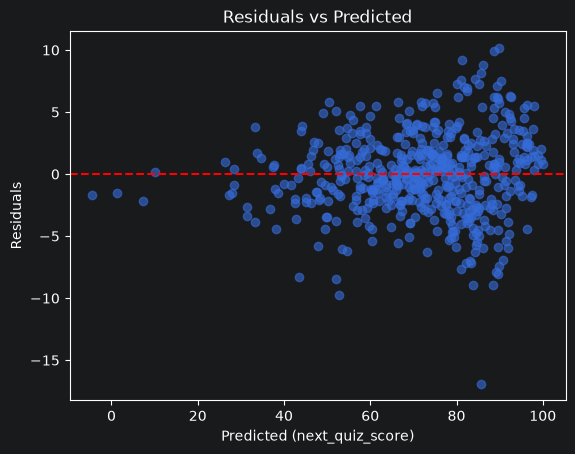

In [36]:
pyplot.scatter(pred_linear, residuals, alpha=0.6)
pyplot.axhline(y=0, color="red", linestyle="--")
pyplot.xlabel("Predicted (next_quiz_score)")
pyplot.ylabel("Residuals")
pyplot.title("Residuals vs Predicted")
pyplot.show()

### 3. Classification

#### 3.1 Define the target and features

In [37]:
num_features = ["days_since_prev_session", "accessibility_nonvoice_enabled", "avg_latency_ms", "tracking_loss_ratio", "session_duration_min", "attention_ratio", "active_time_ratio", "pause_count", "help_request_count", "hint_time_sec", "error_count", "completion_rate", "video_count", "reading_count", "audio_count", "practice_count", "modality_switches", "prev_quiz_mean", "prev_quiz_last", "prev_quiz_attempts", "prior_mastery_level", "confidence_rating", "next_quiz_score", "time_to_mastery_days"]

cat_features = ["day_of_week", "time_of_day", "device_type", "input_mode", "dominant_modality", "split"]

In [38]:
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_features),
    ("cat", categorical_transformer, cat_features),
])

In [39]:
y = xr_learner_sessions_df["support_required"]
x = xr_learner_sessions_df.drop(columns=y.name)

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

#### 3.2 Define the Logistic Regression Pipeline

In [40]:
from sklearn.linear_model import LogisticRegression

logreg_classifier = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

#### 3.3 Perform Grid Search Cross Validation for Logistic Regression

3.3.1 Define the grid

In [41]:
param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

3.3.2 Execute grid search cross validation

In [42]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=logreg_classifier,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(x_train, y_train)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best f1 score: {round(grid_search.best_score_, 3)}")

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters: {'model__C': 0.1}
Best f1 score: 0.363


#### 3.4 Perform Cross-Validation for the number of K in K-Nearest Neighbors

3.4.1 Define the sample set for k values for the knn classifier

In [43]:
k_values = range(1, 31, 2)
rows = []

3.4.2 Perform cross-validation for the logistic regression model

Define pipeline getter

In [44]:
from sklearn.neighbors import KNeighborsClassifier

def get_knn_pipeline(k_value):
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier(n_neighbors=k_value))
    ])

Perform the KNN and get the scores

In [45]:
from sklearn.model_selection import cross_val_score

for k in k_values:
    model = get_knn_pipeline(k)
    scores = cross_val_score(model, x_train, y_train, cv=5, scoring="f1")
    rows.append({"k":k, "Mean F1":scores.mean(), "Standard F1":scores.std()})

3.4.3 Display the results of the cross-validation for the knn classifier

In [46]:
knn_cv_results = pandas.DataFrame(rows)
display(knn_cv_results.round(3))

,k,Mean F1,Standard F1
0,1,0.294,0.030
1,3,0.312,0.021
2,5,0.299,0.021
3,7,0.271,0.040
4,9,0.250,0.062
5,11,0.257,0.075
6,13,0.239,0.057
7,15,0.217,0.059
8,17,0.231,0.058
9,19,0.215,0.078


3.4.4 Plot the results of the cross-validation for the knn classifier

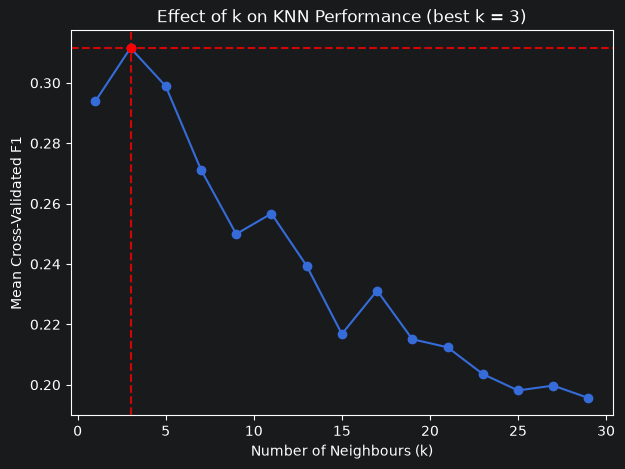

In [47]:
pyplot.figure(figsize=(7,5))
best_k_index = knn_cv_results["Mean F1"].idxmax()
best_k = int(knn_cv_results.loc[best_k_index, "k"])
best_f1 = knn_cv_results.loc[best_k_index, "Mean F1"]
pyplot.plot(knn_cv_results["k"], knn_cv_results["Mean F1"], marker="o")
pyplot.axvline(best_k, color="red", linestyle="--", linewidth=1.5, alpha=0.8)
pyplot.axhline(best_f1, color="red", linestyle="--", linewidth=1.5, alpha=0.8)
pyplot.scatter(best_k, best_f1, color="red", zorder=3)
#pyplot.annotate(f"Best k = {best_k}", xy=(best_k, best_f1), xytext=(best_k + 2, best_f1 + 0.01),arrowprops={"arrowstyle": "->", "color": "red"}, color="red")
pyplot.xlabel("Number of Neighbours (k)")
pyplot.ylabel("Mean Cross-Validated F1")
pyplot.title(f"Effect of k on KNN Performance (best k = {best_k})")
pyplot.show()
#print(f"Best k = {best_k}")


#### 3.5 Get the best Logistic Regression and K-Nearest Neighbors

In [48]:
logreg_classifier = grid_search.best_estimator_
knn_classifier = get_knn_pipeline(k_value=best_k)

#### 3.6 Fit the models with the training dataset

3.6.1 Fit the logistic regression model

In [49]:
logreg_classifier.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['day_of_week','time_of_day','days_since_prev_session',..., 'next_quiz_score','time_to_mastery_days','split']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specif

3.6.2 Fit the K-Nearest Neighbors model

In [50]:
knn_classifier.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['day_of_week','time_of_day','days_since_prev_session',..., 'next_quiz_score','time_to_mastery_days','split']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specif

#### 3.7 Get the confusion matrix for the classification models

3.7.1 Get the predictions for the testing dataset for both models

In [51]:
y_pred_logreg = logreg_classifier.predict(x_test)
y_pred_knn = knn_classifier.predict(x_test)

3.7.2 Get the confusion matrix for the logistic regression model

In [52]:
from sklearn.metrics import confusion_matrix

logreg_confusion_matrix = confusion_matrix(y_test, y_pred_logreg)
knn_confusion_matrix = confusion_matrix(y_test, y_pred_knn)

3.7.3 Display the confusion matrix for the logistic regression model

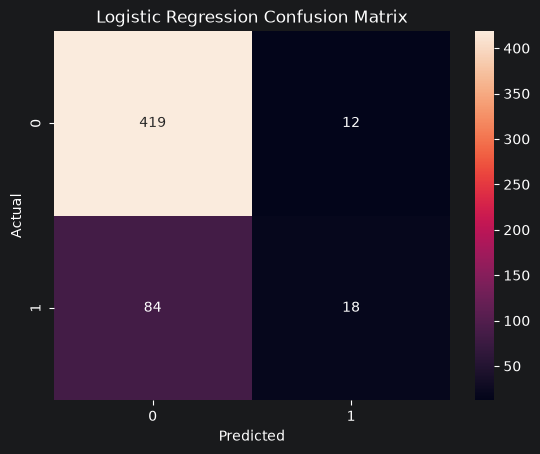

In [53]:
seaborn.heatmap(logreg_confusion_matrix, annot=True, fmt='d')
pyplot.xlabel("Predicted")
pyplot.ylabel("Actual")
pyplot.title("Logistic Regression Confusion Matrix")
pyplot.show()

3.7.4 Display the confusion matrix for the K-Nearest Neighbors model

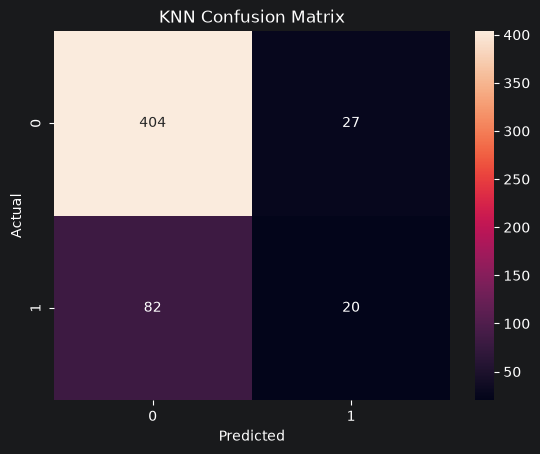

In [54]:
seaborn.heatmap(knn_confusion_matrix, annot=True, fmt='d')
pyplot.xlabel("Predicted")
pyplot.ylabel("Actual")
pyplot.title("KNN Confusion Matrix")
pyplot.show()

#### 3.8 Get the Threshold vs Cost for both models

3.8.1 Get the probabilities for the testing dataset for both modelss

In [55]:
prob_logreg = logreg_classifier.predict_proba(x_test)[:,1]
prob_knn = knn_classifier.predict_proba(x_test)[:,1]

3.8.2 Get the actual values for the testing dataset

In [56]:
y_true = numpy.asarray(y_test)

3.8.3 Set the costs for false positives and false negatives

In [57]:
cost_fp = 1.0   # false positive cost
cost_fn = 5.0   # false negative cost

3.8.4 Set the thresholds to evaluate

In [58]:
thresholds = numpy.linspace(0.0, 1.0, 101)
logreg_thresholds = thresholds
knn_thresholds = thresholds

3.8.5 Define the calculation for the costs for each threshold

In [59]:
def get_threshold_costs(prob):
    threshold_costs = []

    for thresh in thresholds:
        y_thresh_pred = (prob >= thresh).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_thresh_pred, labels=[0, 1]).ravel()
        total_cost = fp * cost_fp + fn * cost_fn
        threshold_costs.append(total_cost / len(y_true))  # cost per sample

    return numpy.array(threshold_costs)

3.8.6 Calculate the costs for Logistic Regression

In [60]:
logreg_costs = get_threshold_costs(prob_logreg)
best_idx_logreg = logreg_costs.argmin()
best_thresh_logreg = logreg_thresholds[best_idx_logreg]
best_cost_logreg = logreg_costs[best_idx_logreg]

3.8.7 Calculate the costs for K-Nearest-Neighbor

In [61]:
knn_costs = get_threshold_costs(prob_knn)
best_idx_knn = knn_costs.argmin()
best_thresh_knn = knn_thresholds[best_idx_knn]
best_cost_knn = knn_costs[best_idx_knn]

3.8.8 Plot threshold vs cost for Logistic Regression

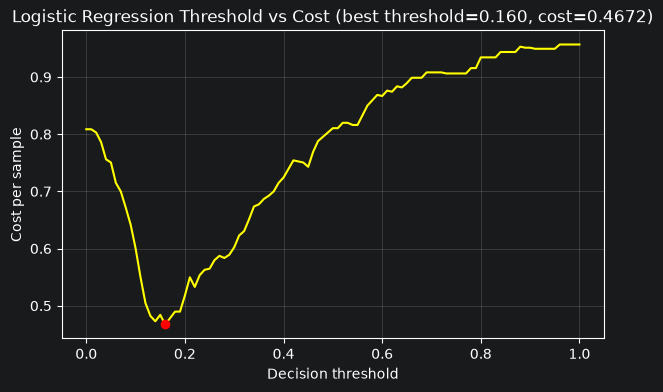

In [62]:
pyplot.figure(figsize=(7,4))
pyplot.plot(logreg_thresholds, logreg_costs, "yellow", label="cost per sample")
pyplot.scatter([best_thresh_logreg], [best_cost_logreg], color="red", zorder=5)
pyplot.xlabel("Decision threshold")
pyplot.ylabel("Cost per sample")
pyplot.title(f"Logistic Regression Threshold vs Cost (best threshold={best_thresh_logreg:.3f}, cost={best_cost_logreg:.4f})")
pyplot.grid(alpha=0.3)
pyplot.show()

3.8.9 Plot threshold vs cost for K-Nearest Neighbor

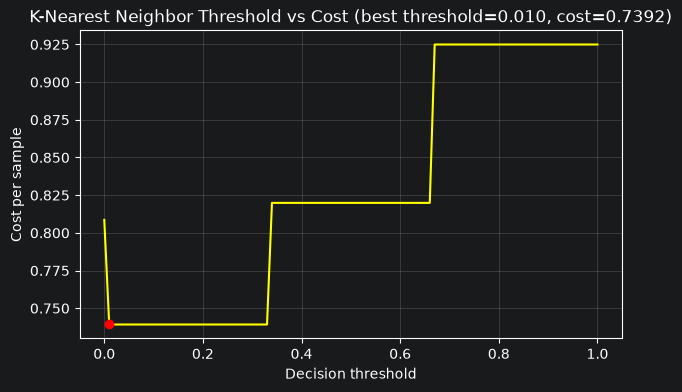

In [63]:
pyplot.figure(figsize=(7,4))
pyplot.plot(knn_thresholds, knn_costs, "yellow", label="cost per sample")
pyplot.scatter([best_thresh_knn], [best_cost_knn], color="red", zorder=5)
pyplot.xlabel("Decision threshold")
pyplot.ylabel("Cost per sample")
pyplot.title(f"K-Nearest Neighbor Threshold vs Cost (best threshold={best_thresh_knn:.3f}, cost={best_cost_knn:.4f})")
pyplot.grid(alpha=0.3)
pyplot.show()

3.8.10 Rework the predictions with best threshold

In [64]:
y_pred_logreg = (prob_logreg >= best_thresh_logreg).astype(int)
y_pred_knn = (prob_knn >= best_thresh_knn).astype(int)

#### 3.9 Get the accuracy, precision, recall, F1 score and ROC AUC score for both models

In [65]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

classifier_model_comparison = pandas.DataFrame({
    "Model": ["Logistic Regression","K-Nearest Neighbors"],
    "Accuracy": [accuracy_score(y_test, y_pred_logreg), accuracy_score(y_test, y_pred_knn)],
    "Precision": [precision_score(y_test, y_pred_logreg), precision_score(y_test, y_pred_knn)],
    "Recall": [recall_score(y_test, y_pred_logreg), recall_score(y_test, y_pred_knn)],
    "F1": [f1_score(y_test, y_pred_logreg), f1_score(y_test, y_pred_knn)],
    "ROC_AUC": [roc_auc_score(y_test, prob_logreg), roc_auc_score(y_test, prob_knn)]
}).round(3)

Display the results

In [66]:
display(classifier_model_comparison)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.690,0.360,0.794,0.495,0.767
1,K-Nearest Neighbors,0.614,0.257,0.539,0.348,0.605


From the result we can see that Logistic Regression has a higher accuracy, precision, recall, F1 score and ROC AUC score than K-Nearest Neighbors. Therefore, for this dataset the Logistic Regression model is the better model, but we will perform cross-validation to confirm this.

#### 3.10 Perform Cross-Validation for both models

In [67]:
CV = 5

3.10.1 Get the average accuracy cross-validation scores for both models using the training dataset

In [68]:
cv_accuracy_logreg = cross_val_score(logreg_classifier, x_train, y_train, cv=CV, scoring="accuracy").mean()
cv_accuracy_knn = cross_val_score(knn_classifier, x_train, y_train, cv=CV, scoring="accuracy").mean()

3.10.2 Get the average precision cross-validation scores for both models using the training dataset

In [69]:
cv_precision_logreg = cross_val_score(logreg_classifier, x_train, y_train, cv=CV, scoring="precision").mean()
cv_precision_knn = cross_val_score(knn_classifier, x_train, y_train, cv=CV, scoring="precision").mean()

3.10.3 Get the average recall cross-validation scores for both models using the training dataset

In [70]:
cv_recall_logreg = cross_val_score(logreg_classifier, x_train, y_train, cv=CV, scoring="recall").mean()
cv_recall_knn = cross_val_score(knn_classifier, x_train, y_train, cv=CV, scoring="recall").mean()

3.10.4 Get the average f1 cross-validation scores for both models using the training dataset

In [71]:
cv_f1_logreg = cross_val_score(logreg_classifier, x_train, y_train, cv=CV, scoring="f1").mean()
cv_f1_knn = cross_val_score(knn_classifier, x_train, y_train, cv=CV, scoring="f1").mean()

3.10.5 Get the average roc_auc cross-validation scores for both models using the training dataset

In [72]:
cv_roc_auc_logreg = cross_val_score(logreg_classifier, x_train, y_train, cv=CV, scoring="roc_auc").mean()
cv_roc_auc_knn = cross_val_score(knn_classifier, x_train, y_train, cv=CV, scoring="roc_auc").mean()

3.10.6 Build the results of the cross-validation for both models

In [73]:
classifier_model_cv_comparison = pandas.DataFrame({
    "Model": ["Logistic Regression","K-Nearest Neighbors"],
    "CV Accuracy": [cv_accuracy_logreg, cv_accuracy_knn],
    "CV Precision": [cv_precision_logreg, cv_precision_knn],
    "CV Recall": [cv_recall_logreg, cv_recall_knn],
    "CV F1": [cv_f1_logreg, cv_f1_knn],
    "CV ROC_AUC": [cv_roc_auc_logreg, cv_roc_auc_knn]
}).round(3)

3.10.7 Display the results of the cross-validation for both models

In [74]:
display(classifier_model_cv_comparison)

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC_AUC
0,Logistic Regression,0.827,0.670,0.252,0.363,0.745
1,K-Nearest Neighbors,0.789,0.443,0.243,0.312,0.614


### 4. Clustering

#### 4.1 Clustering feature engineering

In [75]:
num_features = ["days_since_prev_session", "accessibility_nonvoice_enabled", "avg_latency_ms", "tracking_loss_ratio", "session_duration_min", "attention_ratio", "active_time_ratio", "pause_count", "help_request_count", "hint_time_sec", "error_count", "completion_rate", "video_count", "reading_count", "audio_count", "practice_count", "modality_switches", "prev_quiz_mean", "prev_quiz_last", "prev_quiz_attempts", "prior_mastery_level", "confidence_rating", "next_quiz_score", "time_to_mastery_days", "support_required"]

In [76]:
clustering_preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_features)
])

Only numerical features are considered for clustering

#### 4.2 Define the range for k and metrics

In [77]:
inertia_list = []
silhouette_list = []
k_range = range(2, 10)

#### 4.3 Define K-Means pipeline getter

In [78]:
from sklearn.cluster import KMeans

def get_kmeans_pipeline(k_value):
    return Pipeline([
        ("preprocessor", clustering_preprocessor),
        ("model", KMeans(n_clusters=k_value, random_state=42))
    ])

#### 4.4 Get the numerical data

In [79]:
num_data = xr_learner_sessions_df[num_features]
clustering_preprocessor.fit(num_data)
transformed_data = clustering_preprocessor.transform(num_data)

#### 4.5 Compute and visualize inertia and silhouette scores

4.5.1 Consolidate the required data

In [80]:
from sklearn.metrics import silhouette_score

for k in k_range:
    model = get_kmeans_pipeline(k)
    model.fit(num_data)
    inertia_list.append(model.named_steps["model"].inertia_)
    test_labels = model.fit_predict(num_data)
    silhouette_list.append(silhouette_score(transformed_data, test_labels))

4.5.2 Plot the elbow curve

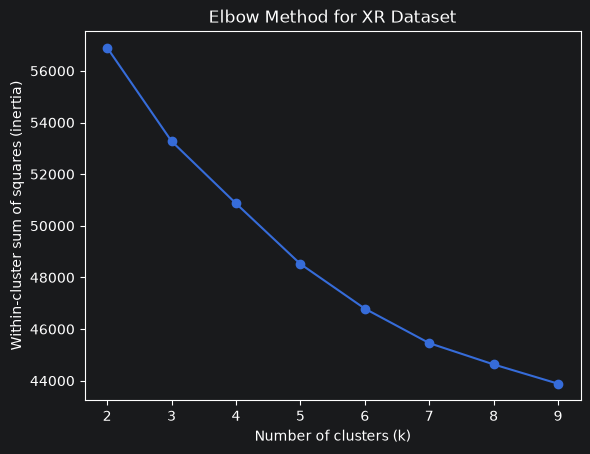

In [81]:
pyplot.plot(k_range, inertia_list, marker='o')
pyplot.xlabel("Number of clusters (k)")
pyplot.ylabel("Within-cluster sum of squares (inertia)")
pyplot.title("Elbow Method for XR Dataset")
pyplot.show()

4.5.3 Plot the silhouette scores

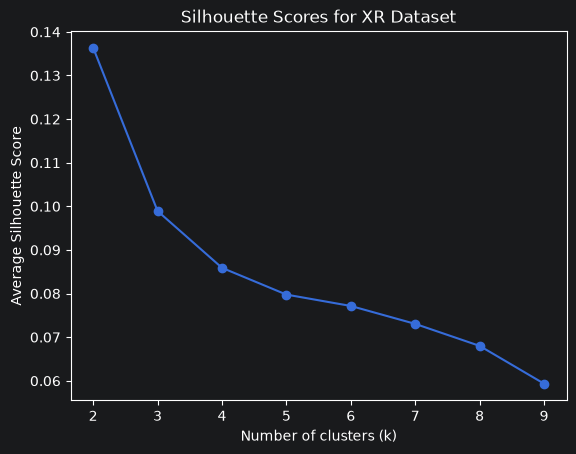

In [82]:
pyplot.plot(k_range, silhouette_list, marker='o')
pyplot.xlabel("Number of clusters (k)")
pyplot.ylabel("Average Silhouette Score")
pyplot.title("Silhouette Scores for XR Dataset")
pyplot.show()

#### 4.6 Evaluate and get the best k value

4.6.1 Tabulate inertia and silhouette scores

In [83]:
k_eval = pandas.DataFrame({
    "k": k_range,
    "Inertia": inertia_list,
    "Silhouette": silhouette_list
})

display(k_eval.round(3))

,k,Inertia,Silhouette
0,2,56897.763,0.136
1,3,53275.025,0.099
2,4,50864.451,0.086
3,5,48521.142,0.080
4,6,46791.231,0.077
5,7,45455.495,0.073
6,8,44630.445,0.068
7,9,43884.312,0.059


4.6.2 Select the best k value

In [84]:
best_idx = k_eval["Silhouette"].idxmax()
best_k = int(k_eval.at[best_idx, 'k'])
print(f"Highest silhouette among tested values: k = {best_k}")

Highest silhouette among tested values: k = 2


#### 4.7 Refit K-Means with best k

4.7.1 Get the final best K-Means model

In [85]:
kmeans_clustering = get_kmeans_pipeline(best_k)
labels = kmeans_clustering.fit_predict(num_data)

4.7.2 Average features per cluster

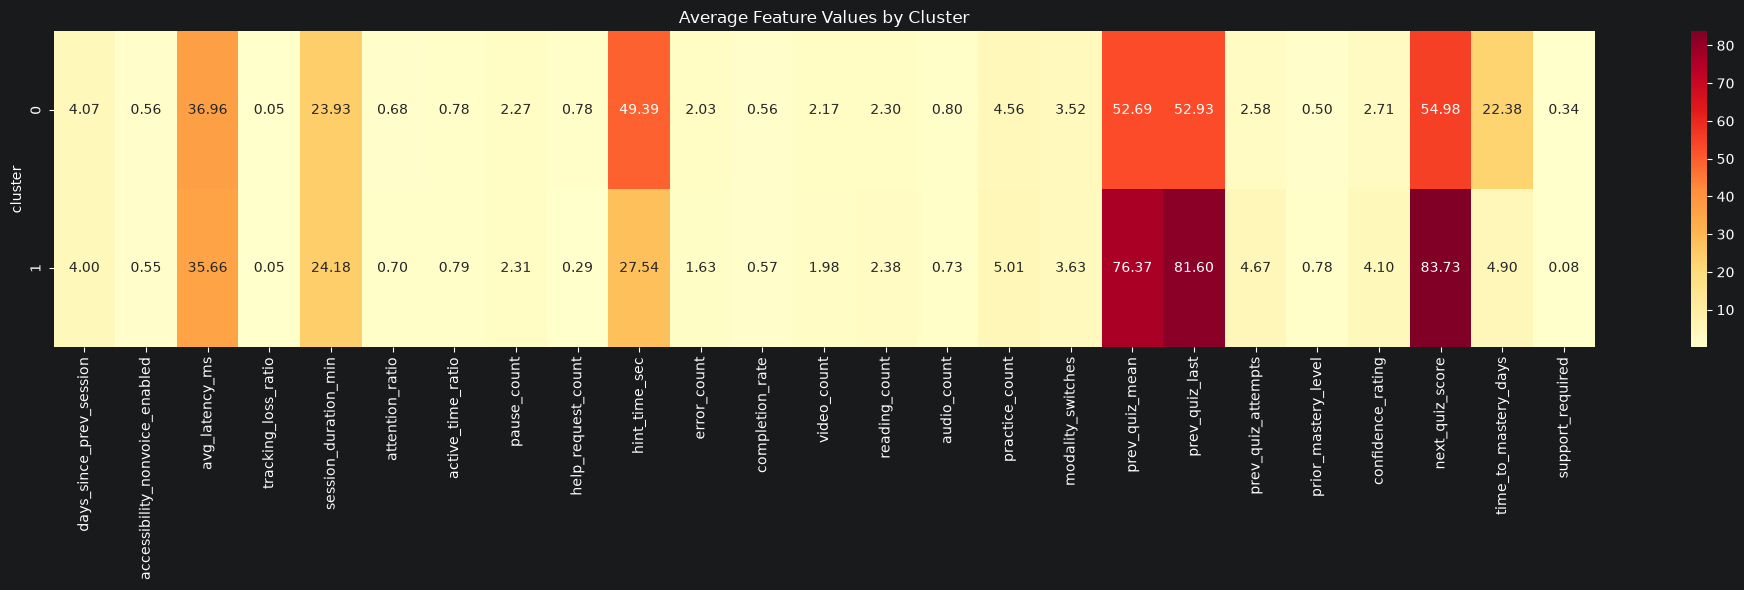

In [86]:
xr_learner_sessions_df["cluster"] = labels
avg_cluster_features = xr_learner_sessions_df.groupby("cluster").mean(numeric_only=True)

pyplot.figure(figsize=(20, 6))

seaborn.heatmap(
    avg_cluster_features,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd"
)

pyplot.title("Average Feature Values by Cluster")
pyplot.tight_layout()
pyplot.show()

4.7.3 Counts per cluster

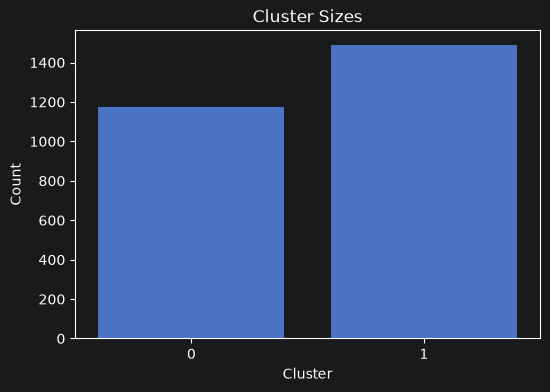

In [87]:
pyplot.figure(figsize=(6, 4))
seaborn.countplot(data=xr_learner_sessions_df, x="cluster")
pyplot.title("Cluster Sizes")
pyplot.xlabel("Cluster")
pyplot.ylabel("Count")
pyplot.show()

4.8 Principal Component Analysis

4.8.1 Get the PCA fit

In [88]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_fit = pca.fit_transform(transformed_data)

4.8.2 Display the PCA fit

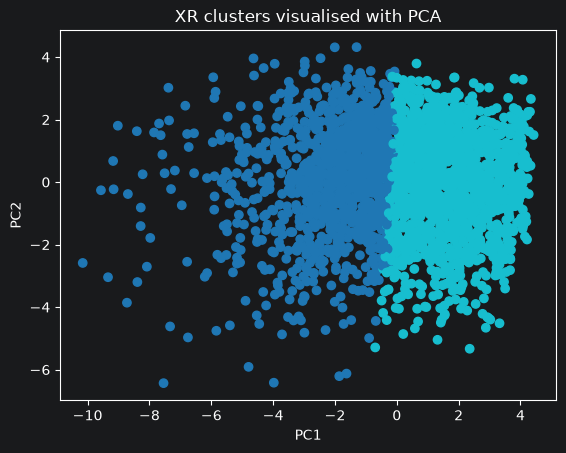

In [89]:
pyplot.scatter(pca_fit[:, 0], pca_fit[:, 1], c = labels, cmap = "tab10")
pyplot.xlabel("PC1")
pyplot.ylabel("PC2")
pyplot.title("XR clusters visualised with PCA")
pyplot.show()

### 5. Association Rule Mining

#### 5.1 Preparing the dataset

5.1.1 Compile bins for numerical features

In [90]:
xr_learner_sessions_df["mastery_bin"] = pandas.qcut(
    xr_learner_sessions_df["prior_mastery_level"],
    q=3,
    labels=["LowMastery", "MediumMastery", "HighMastery"]
)

xr_learner_sessions_df["mastery_time_bin"] = pandas.qcut(
    xr_learner_sessions_df["time_to_mastery_days"],
    q=3,
    labels=["LowTime", "MediumTime", "HighTime"]
)

xr_learner_sessions_df["quiz_bin"] = pandas.qcut(
    xr_learner_sessions_df["next_quiz_score"],
    q=3,
    labels=["LowQuiz", "MediumQuiz", "HighQuiz"]
)

xr_learner_sessions_df["completion_bin"] = pandas.qcut(
    xr_learner_sessions_df["completion_rate"],
    q=3,
    labels=["LowCompletion", "MediumCompletion", "HighCompletion"]
)

xr_learner_sessions_df["attention_bin"] = pandas.qcut(
    xr_learner_sessions_df["attention_ratio"],
    q=3,
    labels=["LowAttention", "MediumAttention", "HighAttention"]
)

5.1.2 Create the transactions data frame

In [91]:
transactions = pandas.DataFrame({
    "device": "Device_" + xr_learner_sessions_df["device_type"].astype(str),
    "input": "Input_" + xr_learner_sessions_df["input_mode"].astype(str),
    "time": "Time_" + xr_learner_sessions_df["time_of_day"].astype(str),
    "day": "Day_" + xr_learner_sessions_df["day_of_week"].astype(str),
    "modality": "Modality_" + xr_learner_sessions_df["dominant_modality"].astype(str),
    "mastery": xr_learner_sessions_df["mastery_bin"].astype(str),
    "mastery_time": xr_learner_sessions_df["mastery_time_bin"].astype(str),
    "quiz": xr_learner_sessions_df["quiz_bin"].astype(str),
    "completion": xr_learner_sessions_df["completion_bin"].astype(str),
    "attention": xr_learner_sessions_df["attention_bin"].astype(str)
})

5.1.3 Encode the transactions and get the item set

In [92]:
from mlxtend.preprocessing import TransactionEncoder

transaction_encoder = TransactionEncoder()
transaction_list = transactions.to_numpy()
encoded_transactions = transaction_encoder.fit_transform(transaction_list)
items = pandas.DataFrame(encoded_transactions, columns=transaction_encoder.columns_)
items.head()

,Day_Fri,Day_Mon,Day_Sat,Day_Sun,Day_Thu,Day_Tue,Day_Wed,Device_AR_Tablet,Device_Desktop_3D,Device_VR_HMD,...,MediumTime,Modality_Audio,Modality_Mixed,Modality_Practice,Modality_Reading,Modality_Video,Time_Afternoon,Time_Evening,Time_Morning,Time_Night
0,False,True,False,False,False,False,False,True,False,False,...,False,False,False,True,False,False,False,True,False,False
1,False,False,False,False,True,False,False,True,False,False,...,False,False,False,True,False,False,False,True,False,False
2,False,False,False,False,False,True,False,False,False,True,...,False,False,False,True,False,False,True,False,False,False
3,False,False,False,False,True,False,False,False,False,True,...,False,False,False,True,False,False,True,False,False,False
4,False,False,False,False,False,True,False,True,False,False,...,False,False,False,True,False,False,True,False,False,False


5.3.4 Check the item set shape

In [93]:
print(f"Items shape: {items.shape}")

Items shape: (2662, 39)


#### 5.2 Mine association rules using Apriori

5.2.1 Get the frequent item sets

In [94]:
from mlxtend.frequent_patterns import apriori

frequent_item_sets = apriori(items, min_support=0.1, use_colnames=True)

print(frequent_item_sets.head())

    support              itemsets
0  0.143501  frozenset({Day_Fri})
1  0.145755  frozenset({Day_Mon})
2  0.140120  frozenset({Day_Sat})
3  0.144252  frozenset({Day_Sun})
4  0.143877  frozenset({Day_Thu})


5.2.2 Get the rules

In [95]:
from mlxtend.frequent_patterns import association_rules

rules = association_rules(frequent_item_sets, metric="confidence", min_threshold=0.5)

#### 5.3 Display the rules

In [96]:
rules_df = rules.copy()

rules_df["antecedents"] = rules_df["antecedents"].apply(
    lambda antecedent: ", ".join(sorted(antecedent))
)

rules_df["consequents"] = rules_df["consequents"].apply(
    lambda consequent: ", ".join(sorted(consequent))
)

rules_df = rules_df[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].sort_values("lift", ascending=False)

rules_df.head(10)

,antecedents,consequents,support,confidence,lift
246,"LowAttention, LowQuiz","HighTime, LowCompletion",0.113449,0.893491,6.681105
243,"HighTime, LowCompletion","LowAttention, LowQuiz",0.113449,0.848315,6.681105
245,"LowCompletion, LowQuiz","HighTime, LowAttention",0.113449,0.870317,6.657425
244,"HighTime, LowAttention","LowCompletion, LowQuiz",0.113449,0.867816,6.657425
263,"LowQuiz, Modality_Practice","HighTime, LowMastery",0.132607,0.865196,2.991106
264,"HighTime, Modality_Practice","LowMastery, LowQuiz",0.132607,0.875931,2.985566
247,"LowAttention, LowMastery, LowQuiz",HighTime,0.108189,0.989691,2.976900
253,"LowCompletion, LowMastery, LowQuiz",HighTime,0.111570,0.986711,2.967937
141,"LowAttention, LowQuiz",HighTime,0.125094,0.985207,2.963414
257,"LowCompletion, LowQuiz","HighTime, LowMastery",0.111570,0.855908,2.958995


### 5. Anormaly Detection

#### 5.1 Get the anomalies

In [97]:
from sklearn.ensemble import IsolationForest

iso_forest = IsolationForest(contamination=0.05, random_state=42)
iso_labels = iso_forest.fit_predict(transformed_data)
xr_learner_sessions_df["is_anomaly"] = iso_labels

full_anomalies = xr_learner_sessions_df[xr_learner_sessions_df["is_anomaly"] == -1]# if -1 then it is an anomaly

#### 5.2 Check anomalies shape

In [98]:
print(f"Anomalies shape: {full_anomalies.shape}")

Anomalies shape: (134, 38)


#### 5.3 Display the selected anomalies

In [99]:
anomalies = full_anomalies.head(3)
required_columns = ["completion_rate", "attention_ratio", "next_quiz_score", "prev_quiz_mean", "confidence_rating", "time_to_mastery_days", "session_duration_min", "avg_latency_ms", "error_count", "tracking_loss_ratio", "is_anomaly"]
anomalies = anomalies[required_columns]
anomalies[required_columns].T

,25,26,45
completion_rate,0.3345,0.4988,0.5528
attention_ratio,0.2457,0.5667,0.7321
next_quiz_score,8.0000,8.2000,81.8000
prev_quiz_mean,46.9600,42.0900,82.4000
confidence_rating,3.0000,2.0000,4.0000
time_to_mastery_days,72.6200,67.5700,0.6600
session_duration_min,18.9600,33.3100,49.2100
avg_latency_ms,80.9000,30.2000,97.3000
error_count,11.0000,2.0000,5.0000
tracking_loss_ratio,0.1310,0.0067,0.0842
